# Week 6 · Task C — The figure the board will actually see
**One figure · one message · one named reader · 5 marks**

**Reader:** the board of the National Grid Authority, splitting a reliability budget across 24 districts.
**Question:** *where is supply least reliable?* — not where are there most interruptions, but where is **service worst**.

**The figure:** an equal-area choropleth **beside** a sorted bar chart, both of **interruptions per 1,000 households**. The map shows *where*; the bars give the five most populous districts (12.6 % of the land, 59.9 % of the people) the ink a choropleth takes from them, and let the reader see the ranking without doing arithmetic. Raw counts appear only as a marker — rings on the map, a label on the bars — so the counterfactual is visible in the figure itself.

> Run **Task A** first: this notebook reads only `clean/district_grid.csv` and `data/regions.geojson`.

In [ ]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

def find_root():
    """Folder that holds the three toolkits and data/ - works from week6/assignments or a copy of it."""
    here = Path.cwd().resolve()
    for base in [here, here / "assignments", here.parent, here.parent / "assignments"]:
        if (base / "vizlib.py").exists() and (base / "data").is_dir():
            return base
    raise FileNotFoundError("Open this notebook in the folder that contains vizlib.py, tslib.py, geolib.py and data/")

ROOT = find_root()
sys.path.insert(0, str(ROOT))
DATA, CLEAN = ROOT / "data", ROOT / "clean"
CLEAN.mkdir(exist_ok=True)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import vizlib, geolib
from vizlib import PALETTE
vizlib.style_defaults()
assert (CLEAN / "district_grid.csv").exists(), "Run Task_A_process.ipynb first"
reg = pd.read_csv(CLEAN / "district_grid.csv")
feats = geolib.read_geojson(DATA / "regions.geojson")
reg["rate"] = reg.outages / reg.households * 1000
pooled = reg.outages.sum() / reg.households.sum() * 1000
print(len(reg), "districts |", f"{reg.outages.sum():,} interruptions |", f"{reg.households.sum():,} households | pooled {pooled:.1f} per 1,000 households")

24 districts | 388,879 interruptions | 8,908,512 households | pooled 43.7 per 1,000 households


## 1 · The anchors — do the numbers behave as the brief says?

In [ ]:
r_cnt = np.corrcoef(reg.outages, reg.households)[0, 1]
r_rate = np.corrcoef(reg.rate, reg.households)[0, 1]
top_cnt = reg.nlargest(3, "outages").code.tolist(); top_rate = reg.nlargest(3, "rate").code.tolist()
both = sorted(set(top_cnt) & set(top_rate))
top5 = reg.nlargest(5, "population")
area = {f["code"]: geolib.polygon_area_km2(f["ring"]) for f in feats}                 # area from the geometry, projected - never degrees
land5 = sum(area[c] for c in top5.code) / sum(area.values()); pop5 = top5.population.sum() / reg.population.sum()
rows = [("r(interruptions, households)", f"{r_cnt:+.3f}", "+0.991"), ("r(rate per 1,000 households, households)", f"{r_rate:+.3f}", "+0.175"),
        ("top 3 by COUNT", ", ".join(top_cnt), "D17, D13, D24"), ("top 3 by RATE", ", ".join(top_rate), "D12, D11, D13"),
        ("districts on both lists", f"{len(both)} ({', '.join(both)})", "1"), ("national pooled rate", f"{pooled:.1f}", "43.7"),
        ("5 most populous: land / people", f"{land5:.1%} / {pop5:.1%}", "12.6% / 59.9%")]
pd.DataFrame(rows, columns=["check", "ours", "expected"])

,check,ours,expected
0,"r(interruptions, households)",+0.991,+0.991
1,"r(rate per 1,000 households, households)",+0.175,+0.175
2,top 3 by COUNT,"D17, D13, D24","D17, D13, D24"
3,top 3 by RATE,"D12, D11, D13","D12, D11, D13"
4,districts on both lists,1 (D13),1
5,national pooled rate,43.7,43.7
6,5 most populous: land / people,12.6% / 59.9%,12.6% / 59.9%


Counts track size almost perfectly (r = +0.99): a count map is a map of where people live. Once the denominator is households that correlation collapses to +0.18 and the ranking changes — **one** district, D13 Mehrabad, survives on both lists. The next cell asks why.

In [ ]:
d13 = reg[reg.code == "D13"].iloc[0]
rk = lambda col, c: int(reg[col].rank(ascending=False)[reg.code == c].iloc[0])
print(f"D13 Mehrabad: {d13.households:,.0f} households (rank {rk('households','D13')} of 24), income USD {d13.income_pc_usd:,} per head "
      f"(rank {int(reg.income_pc_usd.rank(ascending=True)[reg.code=='D13'].iloc[0])} lowest of 24), rate {d13.rate:.1f}")
for c in ("D17", "D24"):
    r = reg[reg.code == c].iloc[0]
    print(f"{c} {r.district}: {r.households:,.0f} households (rank {rk('households', c)}), income USD {r.income_pc_usd:,}, rate {r.rate:.1f} -> {'below' if r.rate < pooled else 'above'} the national {pooled:.1f}")
rho = reg[["rate", "income_pc_usd", "electrification_pct"]].corr(method="spearman")
print(f"Spearman rho(rate, income) = {rho.loc['rate','income_pc_usd']:.2f};  rho(rate, electrification, n=21) = {rho.loc['rate','electrification_pct']:.2f}")
print("=> D13 is on both lists because it is BIG (1.11 M households) AND POOR (USD 2,600, tied lowest); D17 and D24 are on the count list only because they are big.")

# is the difference signal or noise?  Poisson funnel limits on households
fl = geolib.funnel_limits(reg.households, pooled, per=1000)
fl = reg.merge(fl, left_on="households", right_on="population")
out_hi, out_lo = fl[fl.rate > fl.hi], fl[fl.rate < fl.lo]
print(f"funnel (95%, Poisson): {len(out_hi)} districts above the upper limit, {len(out_lo)} below the lower, {len(fl)-len(out_hi)-len(out_lo)} inside; "
      f"smallest district has {reg.outages.min():,} interruptions behind its rate -> no district is too small to publish.")
print("above the funnel:", out_hi.sort_values('rate', ascending=False).code.tolist())

D13 Mehrabad: 1,110,000 households (rank 2 of 24), income USD 2,600 per head (rank 1 lowest of 24), rate 50.3
D17 Qilabad: 1,566,571 households (rank 1), income USD 8,150, rate 40.4 -> below the national 43.7
D24 Zhobara: 1,028,226 households (rank 3), income USD 5,050, rate 42.5 -> below the national 43.7
Spearman rho(rate, income) = -0.72;  rho(rate, electrification, n=21) = -0.64
=> D13 is on both lists because it is BIG (1.11 M households) AND POOR (USD 2,600, tied lowest); D17 and D24 are on the count list only because they are big.
funnel (95%, Poisson): 8 districts above the upper limit, 14 below the lower, 2 inside; smallest district has 3,234 interruptions behind its rate -> no district is too small to publish.
above the funnel: ['D12', 'D11', 'D13', 'D18', 'D03', 'D21', 'D14', 'D22']


## 2 · The figure

*Parameters, each with a reason (repeated in `partC_note.md`):* **denominator** = households (the unit that is billed and that an interruption interrupts; population would add the 5.70–7.36 persons-per-household spread as noise) · **classes** = Jenks natural breaks, k = 5, printed below (the rates are tightly bunched, so equal intervals would leave two classes empty and quantiles would invent gradient) · **colour** = single-hue sequential Blues, never a rainbow · **projection** = Lambert cylindrical equal-area (area is what a choropleth encodes), one reference latitude for the whole map · **axis order** = bars sorted by rate, highest on top, **zero baseline** · **window** = the register's 12 months · **no district suppressed or merged**.

Jenks class breaks (per 1,000 households): [30.4, 33.5, 36.2, 42.7, 45.8, 50.9] | goodness of variance fit: 0.959
deutan simulation
  #6baed6  ->  #8DA1D5
  #08519c  ->  #004C9B
  #D55E00  ->  #9E8C00
  #16202E  ->  #181E2E


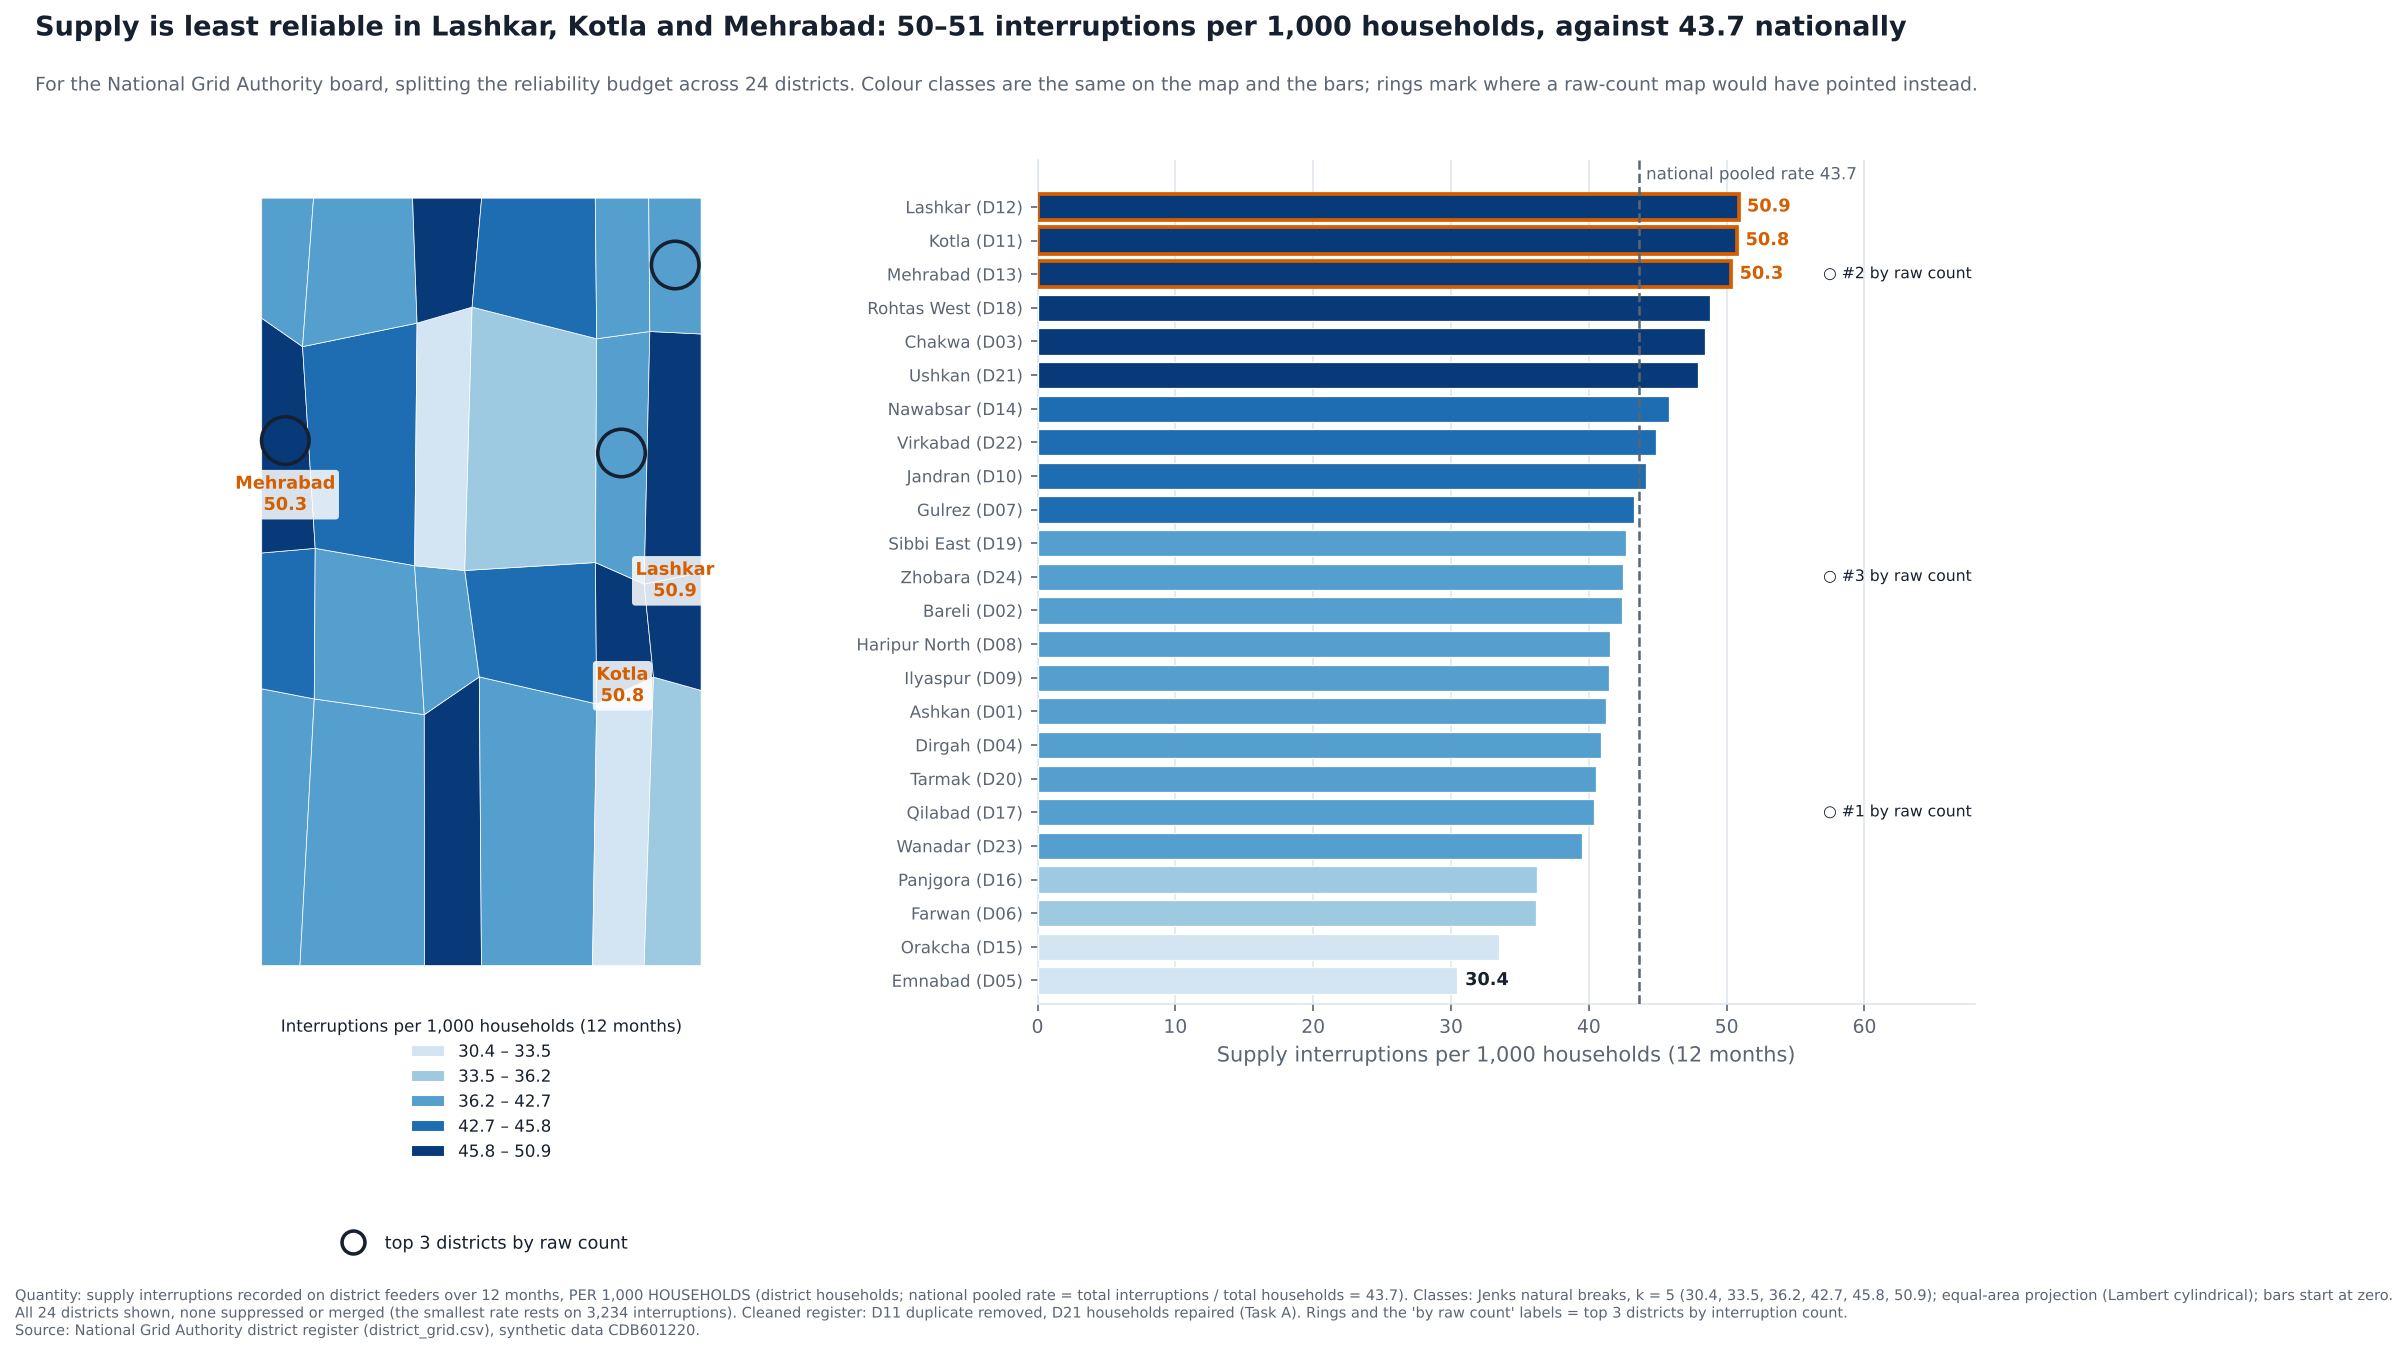

In [ ]:
vals = reg.set_index("code").rate.to_dict()
ordered = reg.sort_values("rate").reset_index(drop=True)
edges = geolib.breaks(reg.rate.to_numpy(), scheme="natural", k=5)
print("Jenks class breaks (per 1,000 households):", [round(e, 1) for e in edges], "| goodness of variance fit:", round(geolib.gvf(reg.rate.to_numpy(), edges), 3))
cls = geolib.class_of(ordered.rate.to_numpy(), edges)
cm = plt.get_cmap(PALETTE["sequential"]); shades = [cm(0.18 + 0.78 * c / 4) for c in range(5)]
ink, hl = PALETTE["ink"], PALETTE["highlight"]
_ = vizlib.cvd_report([PALETTE["sequential"] and "#6baed6", "#08519c", hl, "#16202E"], "deutan")

top3_rate = reg.nlargest(3, "rate"); top3_cnt = reg.nlargest(3, "outages").code.tolist()
fig = plt.figure(figsize=(13.4, 8.4))
gs = GridSpec(1, 2, width_ratios=[1.0, 1.05], wspace=0.12, left=0.02, right=0.985, top=0.86, bottom=0.19)
axm, axb = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

# ---- map ---------------------------------------------------------------------
geolib.choropleth(axm, feats, vals, scheme="natural", k=5, legend_title="Interruptions per 1,000 households (12 months)",
                  fmt="{:.1f}", legend_loc="upper center", legend_anchor=(0.5, 0.0))
leg1 = axm.get_legend(); axm.add_artist(leg1)
lat_ts = geolib._collection_lat_ts(feats)
px, py = geolib.equal_area_xy(reg.lon.to_numpy(), reg.lat.to_numpy(), lat_ts=lat_ts)
pos = dict(zip(reg.code, zip(px, py)))
ring = axm.scatter([pos[c][0] for c in top3_cnt], [pos[c][1] for c in top3_cnt], s=520, facecolor="none", edgecolor=ink, lw=1.7, zorder=6)
for _, r in top3_rate.iterrows():
    axm.annotate(f"{r.district}\n{r.rate:.1f}", pos[r.code], xytext=(0, -26 if r.code != "D12" else 24), textcoords="offset points", ha="center", va="center",
                 fontsize=8.5, fontweight="bold", color=hl, bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85), zorder=7)
from matplotlib.lines import Line2D
axm.legend(handles=[Line2D([], [], marker="o", ls="none", mfc="none", mec=ink, mew=1.7, ms=11, label="top 3 districts by raw count")], loc="upper center", bbox_to_anchor=(0.5, -0.255), frameon=False, fontsize=8.5)

# ---- bars --------------------------------------------------------------------
y = np.arange(len(ordered))
axb.barh(y, ordered.rate, color=[shades[c] for c in cls], edgecolor=[hl if c in set(top3_rate.code) else "white" for c in ordered.code],
         linewidth=[1.8 if c in set(top3_rate.code) else 0.6 for c in ordered.code], height=0.78, zorder=3)
axb.set_yticks(y); axb.set_yticklabels([f"{d} ({c})" for d, c in zip(ordered.district, ordered.code)], fontsize=8)
axb.set_xlim(0, 68); axb.set_ylim(-0.7, len(ordered) + 0.4); axb.set_xlabel("Supply interruptions per 1,000 households (12 months)")
axb.axvline(pooled, color=PALETTE["ink_soft"], lw=1.2, ls="--", zorder=4)
axb.text(pooled + 0.5, len(ordered) - 0.05, f"national pooled rate {pooled:.1f}", ha="left", va="center", fontsize=8, color=PALETTE["ink_soft"])
cnt_rank = reg.outages.rank(ascending=False).astype(int).set_index("code") if False else pd.Series(reg.outages.rank(ascending=False).astype(int).values, index=reg.code)
for i, r in ordered.iterrows():
    if r.code in set(top3_rate.code) or i == 0:
        axb.text(r.rate + 0.6, i, f"{r.rate:.1f}", va="center", fontsize=8.5, fontweight="bold", color=hl if r.code in set(top3_rate.code) else ink)
    if r.code in top3_cnt:
        axb.text(57, i, f"\u25cb #{cnt_rank[r.code]} by raw count", va="center", fontsize=7.5, color=ink)
axb.grid(axis="y", visible=False)

fig.suptitle(f"Supply is least reliable in {top3_rate.district.iloc[0]}, {top3_rate.district.iloc[1]} and {top3_rate.district.iloc[2]}: "
             f"{top3_rate.rate.min():.0f}\u2013{top3_rate.rate.max():.0f} interruptions per 1,000 households, against {pooled:.1f} nationally",
             x=0.02, y=0.975, ha="left", fontsize=13, fontweight="bold")
fig.text(0.02, 0.915, "For the National Grid Authority board, splitting the reliability budget across 24 districts. Colour classes are the same on the map and the bars; "
         "rings mark where a raw-count map would have pointed instead.", fontsize=9, color=PALETTE["ink_soft"])
note = (f"Quantity: supply interruptions recorded on district feeders over 12 months, PER 1,000 HOUSEHOLDS (district households; national pooled rate = total interruptions / total households = {pooled:.1f}). "
        f"Classes: Jenks natural breaks, k = 5 ({', '.join(f'{e:.1f}' for e in edges)}); equal-area projection (Lambert cylindrical); bars start at zero.\n"
        f"All 24 districts shown, none suppressed or merged (the smallest rate rests on {reg.outages.min():,} interruptions). Cleaned register: D11 duplicate removed, D21 households repaired (Task A). "
        f"Rings and the 'by raw count' labels = top 3 districts by interruption count.\n"
        f"Source: National Grid Authority district register (district_grid.csv), synthetic data CDB601220.")
vizlib.save_fig(fig, ROOT / "partC_figure.png", note=note)
plt.show()

## 3 · The counterfactual and the ethics clause, in numbers

In [ ]:
# What the raw-count version would have pointed at, and who would lose money.
# ILLUSTRATIVE rule (the board chooses the real one): money follows interruptions ABOVE what the national rate would predict.
reg["excess"] = (reg.households * (reg.rate - pooled) / 1000).clip(lower=0)              # interruptions above the national rate
reg["share_count"] = reg.outages / reg.outages.sum() * 100                                 # what a count map would send
reg["share_excess"] = reg.excess / reg.excess.sum() * 100                                  # what the rate map would send
reg["delta_pp"] = reg.share_excess - reg.share_count                                       # + : the count version takes money AWAY
cf = reg.sort_values("delta_pp")[["code", "district", "households", "outages", "rate", "share_count", "share_excess", "delta_pp"]].round(1)
losers = reg[reg.delta_pp > 0].sort_values("delta_pp", ascending=False)
winners = reg[(reg.delta_pp < 0)].sort_values("delta_pp")
print(f"count version's top 3: {top_cnt}  -> rates {[round(vals[c],1) for c in top_cnt]} vs national {pooled:.1f}")
print(f"rate version's top 3 : {top_rate} -> counts {[int(reg.set_index('code').outages[c]) for c in top_rate]}")
print(f"districts above the national rate: {int((reg.rate>pooled).sum())}; at or below: {int((reg.rate<=pooled).sum())}")
print("\nthe count version takes money AWAY from (share of budget under a rate rule minus under a count rule, percentage points):")
print(losers[["code", "district", "rate", "share_count", "share_excess", "delta_pp"]].round(1).to_string(index=False))
print("\nand gives money TO districts at or below the national rate:", winners[winners.rate <= pooled][["code", "district"]].assign(rate=lambda d: winners.rate.round(1)).values.tolist()[:6])
cf.tail(8)

count version's top 3: ['D17', 'D13', 'D24']  -> rates [40.4, 50.3, 42.5] vs national 43.7
rate version's top 3 : ['D12', 'D11', 'D13'] -> counts [12067, 31283, 55879]
districts above the national rate: 9; at or below: 15

the count version takes money AWAY from (share of budget under a rate rule minus under a count rule, percentage points):
code    district  rate  share_count  share_excess  delta_pp
 D13    Mehrabad  50.3         14.4          44.2      29.8
 D11       Kotla  50.8          8.0          26.1      18.1
 D12     Lashkar  50.9          3.1          10.2       7.1
 D18 Rohtas West  48.8          2.8           6.9       4.0
 D03      Chakwa  48.4          2.1           4.9       2.7
 D21      Ushkan  47.9          2.2           4.6       2.4
 D14    Nawabsar  45.8          0.9           1.0       0.1

and gives money TO districts at or below the national rate: [['D17', 'Qilabad', 40.4], ['D24', 'Zhobara', 42.5], ['D09', 'Ilyaspur', 41.4], ['D01', 'Ashkan', 41.3], ['D08', 'H

,code,district,households,outages,rate,share_count,share_excess,delta_pp
21,D22,Virkabad,188857,8479,44.9,2.2,1.4,-0.8
13,D14,Nawabsar,76721,3515,45.8,0.9,1.0,0.1
20,D21,Ushkan,182000,8719,47.9,2.2,4.6,2.4
2,D03,Chakwa,170859,8276,48.4,2.1,4.9,2.7
17,D18,Rohtas West,225481,10997,48.8,2.8,6.9,4.0
11,D12,Lashkar,237190,12067,50.9,3.1,10.2,7.1
10,D11,Kotla,616114,31283,50.8,8.0,26.1,18.1
12,D13,Mehrabad,1110000,55879,50.3,14.4,44.2,29.8


In [ ]:
# ---- partC_note.md : half a page, written from the numbers above ------------------
nm = reg.set_index("code").district
rate = reg.set_index("code").rate
lost = losers.head(4); lost_txt = ", ".join(f"{r.district} ({r.code}, {r.delta_pp:+.1f} pp)" for _, r in lost.iterrows())
won_below = [c for c in top_cnt + reg.nlargest(5, "outages").code.tolist() if rate[c] <= pooled]
won_below = list(dict.fromkeys(won_below))
won_txt = ", ".join(f"{nm[c]} ({c}, rate {rate[c]:.1f})" for c in won_below)
d13 = reg.set_index("code").loc["D13"]
note_md = f"""# Part C note

**Figure:** `partC_figure.png` (runs from `Task_C_figure.ipynb`; 300 dpi; source note on the figure).

**Message, in one sentence.** Supply is least reliable in {nm['D12']}, {nm['D11']} and {nm['D13']} \u2014 about {top3_rate.rate.min():.0f}\u2013{top3_rate.rate.max():.0f} interruptions per 1,000 households against {pooled:.1f} nationally \u2014 so the board should look there first rather than at the districts with the most interruptions.
**Reader:** the National Grid Authority board splitting the reliability budget across 24 districts.

**What the figure is per.** Interruptions *per 1,000 households* over the register's 12 months, in the legend and the axis title. The national rate is pooled (total interruptions \u00f7 total households), not an average of 24 rates.

**Parameters and why**
- *Denominator = households.* Households are what an interruption interrupts and what is billed; population adds a 5.70\u20137.36 persons-per-household spread as noise.
- *Classes = Jenks, k = 5* ({', '.join(f'{e:.1f}' for e in edges)}). The rates are bunched between {reg.rate.min():.0f} and {reg.rate.max():.0f}; equal intervals leave empty classes and quantiles would invent a five-level gradient from near-equal values. Breaks are printed on the figure.
- *Scheme = single-hue sequential Blues,* same shades on the map and the bars; a rainbow would imply categories.
- *Projection = Lambert cylindrical equal-area* with one reference latitude, because area is the channel a choropleth encodes.
- *Bars sorted by rate, highest on top, zero baseline;* no second axis. *Window* = the register's 12 months.
- *Map plus bars* because the five most populous districts hold {pop5:.1%} of the people on {land5:.1%} of the land: the choropleth gives them a twelfth of the ink, the bars restore it.

**The counterfactual.** A raw-count version names {nm[top_cnt[0]]} ({top_cnt[0]}), {nm[top_cnt[1]]} ({top_cnt[1]}) and {nm[top_cnt[2]]} ({top_cnt[2]}), which is a map of where people live (r = {r_cnt:+.2f} with households). Only {', '.join(nm[c] for c in both)} ({', '.join(both)}) appears on both lists; {nm['D17']} and {nm['D24']} are named only because they are large and have rates of {rate['D17']:.1f} and {rate['D24']:.1f}, both below the national {pooled:.1f}. The rate map instead points at {nm['D12']} ({rate['D12']:.1f}), {nm['D11']} ({rate['D11']:.1f}) and {nm['D13']} ({rate['D13']:.1f}). Why {nm['D13']} is on both lists is the finding: it is large ({d13.households/1e6:.2f} M households) *and* poor (USD {d13.income_pc_usd:,} per head, tied lowest); across the 24 districts r(rate, income) = {np.corrcoef(reg.income_pc_usd, reg.rate)[0,1]:+.2f} (observational, not causal).

**Ethics clause: who would lose money.** If the budget followed raw counts instead of interruptions above the national rate (an *illustrative* rule \u2014 the board chooses the real one), the count version would take the most away from {lost_txt} (even {nm['D13']}, which a count map also flags, would get far less than its excess);  it would give money to districts that are already at or below the national rate, e.g. {won_txt}. {len(reg[reg.rate > pooled])} of 24 districts are above the national rate.
**Suppression:** none. No district was suppressed or merged; the smallest rate rests on {reg.outages.min():,} interruptions, and with Poisson funnel limits (95%) {len(out_hi)} districts sit above the upper limit and {len(out_lo)} below the lower. The Poisson limits ignore over-dispersion and so flatter the precision; the ranking among the top three is within a point and should be read as a group, not as 1-2-3.
"""
(ROOT / "partC_note.md").write_text(note_md, encoding="utf-8")
print(note_md)

# Part C note

**Figure:** `partC_figure.png` (runs from `Task_C_figure.ipynb`; 300 dpi; source note on the figure).

**Message, in one sentence.** Supply is least reliable in Lashkar, Kotla and Mehrabad — about 50–51 interruptions per 1,000 households against 43.7 nationally — so the board should look there first rather than at the districts with the most interruptions.
**Reader:** the National Grid Authority board splitting the reliability budget across 24 districts.

**What the figure is per.** Interruptions *per 1,000 households* over the register's 12 months, in the legend and the axis title. The national rate is pooled (total interruptions ÷ total households), not an average of 24 rates.

**Parameters and why**
- *Denominator = households.* Households are what an interruption interrupts and what is billed; population adds a 5.70–7.36 persons-per-household spread as noise.
- *Classes = Jenks, k = 5* (30.4, 33.5, 36.2, 42.7, 45.8, 50.9). The rates are bunched between 30 and 51; equ

## Self-check against the brief

| Requirement | Where |
|---|---|
| Runs from a script/notebook, exports 300 dpi, source note on the figure | `vizlib.save_fig(..., note=…)` → `partC_figure.png` |
| Quantity normalized, denominator named **in words** in legend and axis | “per 1,000 households” in the map legend, the bar axis and the note |
| Message in one sentence + reader | title, sub-title and `partC_note.md` |
| Parameters each with a reason (denominator, breaks, scheme, projection, axis order, window) | the paragraph above the figure and `partC_note.md` |
| Counterfactual: what the raw-count figure shows and **which districts** | rings on the figure; section 3; `partC_note.md` |
| Ethics clause: who loses money; any suppression | section 3 and the note — nothing suppressed, count = 0 |